In [56]:
text = ['all that we are is a result of what we have thought',
'To be or not to be is the question',
'Be yourself everyone else is already taken']

In [57]:
import re
re.split(r'\s+', text[0])

['all',
 'that',
 'we',
 'are',
 'is',
 'a',
 'result',
 'of',
 'what',
 'we',
 'have',
 'thought']

In [58]:
' '.join(re.split(r'\s+', text[0]))

'all that we are is a result of what we have thought'

In [59]:
allwords = re.split(r'\s+', ' '.join(text).lower())
allwords


['all',
 'that',
 'we',
 'are',
 'is',
 'a',
 'result',
 'of',
 'what',
 'we',
 'have',
 'thought',
 'to',
 'be',
 'or',
 'not',
 'to',
 'be',
 'is',
 'the',
 'question',
 'be',
 'yourself',
 'everyone',
 'else',
 'is',
 'already',
 'taken']

In [60]:
vocab = sorted(set(allwords))
vocab

['a',
 'all',
 'already',
 'are',
 'be',
 'else',
 'everyone',
 'have',
 'is',
 'not',
 'of',
 'or',
 'question',
 'result',
 'taken',
 'that',
 'the',
 'thought',
 'to',
 'we',
 'what',
 'yourself']

In [61]:
word2idx ={}
for i,word in enumerate(vocab):
    word2idx[word] = i
word2idx    

{'a': 0,
 'all': 1,
 'already': 2,
 'are': 3,
 'be': 4,
 'else': 5,
 'everyone': 6,
 'have': 7,
 'is': 8,
 'not': 9,
 'of': 10,
 'or': 11,
 'question': 12,
 'result': 13,
 'taken': 14,
 'that': 15,
 'the': 16,
 'thought': 17,
 'to': 18,
 'we': 19,
 'what': 20,
 'yourself': 21}

In [62]:
idx2word={}
for i,word in enumerate(vocab):
    idx2word[i] = word
idx2word

{0: 'a',
 1: 'all',
 2: 'already',
 3: 'are',
 4: 'be',
 5: 'else',
 6: 'everyone',
 7: 'have',
 8: 'is',
 9: 'not',
 10: 'of',
 11: 'or',
 12: 'question',
 13: 'result',
 14: 'taken',
 15: 'that',
 16: 'the',
 17: 'thought',
 18: 'to',
 19: 'we',
 20: 'what',
 21: 'yourself'}

In [63]:
# generate random indices
import numpy as np

randidx = np.random.randint(0, len(vocab), 5)
randidx

array([ 8, 13, 16,  3,  6])

In [64]:
#index to words
[idx2word[i] for i in randidx]

['is', 'result', 'the', 'are', 'everyone']

In [65]:
#words to index
[word2idx[idx2word[i]] for i in randidx]

[8, 13, 16, 3, 6]

In [66]:
target_word = 'to'
target_idx = word2idx[target_word]

#find all indices of the target word
target_locs = np.where(np.array(allwords) == target_word)[0]
print(f'"{target_word}" appears at indices: {target_locs}')

for t in target_locs:
    print(allwords[t-1:t+2])  # print 2 words before and after the target word

"to" appears at indices: [12 16]
['thought', 'to', 'be']
['not', 'to', 'be']


In [67]:
['all',
 'that',
 'we',
 'are',
 'is',
 'a',
 'result',
 'of',
 'what',
 'we',
 'have',
 'thought',
 'to',
 'be',
 'or',
 'not',
 'to',
 'be',
 'is',
 'the',
 'question',
 'be',
 'yourself',
 'everyone',
 'else',
 'is',
 'already',
 'taken']

['all',
 'that',
 'we',
 'are',
 'is',
 'a',
 'result',
 'of',
 'what',
 'we',
 'have',
 'thought',
 'to',
 'be',
 'or',
 'not',
 'to',
 'be',
 'is',
 'the',
 'question',
 'be',
 'yourself',
 'everyone',
 'else',
 'is',
 'already',
 'taken']

# one hot endoding

#just like getdummies in pandas, we can create a one-hot encoding matrix for our words. Each row will represent a word in the text, and each column will represent a word in the vocabulary. A value of 1 indicates the presence of the word, while 0 indicates its absence

In [68]:
import matplotlib.pyplot as plt

In [69]:
word_matrix = np.zeros((len(allwords), len(vocab)), dtype=int)
for i,word in enumerate(allwords):
    word_matrix[i, word2idx[word]] = 1
print(word_matrix)    

[[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]
 [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0

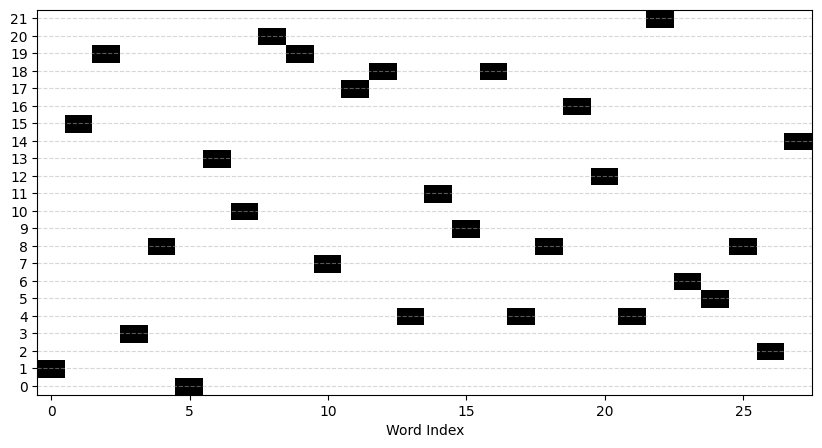

In [70]:
_,ax = plt.subplots(1, figsize=(10,5))
plt.imshow(1-word_matrix.T, origin = 'lower', cmap='gray', aspect='auto')
ax.set(xlabel='Word Index', yticks=range(len(vocab)))
ax.grid(linestyle='--',axis ='y', alpha=0.5)
plt.show()

In [71]:
# encoder function (using for-loop instead of list-comp)
def encoder(words,encode_dict):

  # initialize a vector of numerical indices
  idxs = np.zeros(len(words),dtype=int)

  # loop through the words and find their token in the vocab
  for i,w in enumerate(words):
    idxs[i] = encode_dict[w]

  # return the indices!
  return idxs


# also need a decoder function
def decoder(idxs,decode_dict):
  return ' '.join([decode_dict[i] for i in idxs])